# Numerical Solution of the Blasius Boundary Value Problem Using RK3 and RK4

**Student:** Anbucheran S  
**Student ID:** SC26M005  
**Course:** Scientific Computing Lab  

---

## Abstract

The Blasius boundary-layer equation is a nonlinear third-order ordinary differential equation describing the self-similar velocity distribution in a steady, incompressible laminar boundary layer over a flat plate. The equation is a boundary value problem because its conditions are specified at the wall and in the far field. In this work, the equation is converted into a system of three first-order equations and solved using the shooting method. The resulting initial-value problem is integrated using the third-order Kutta method (RK3) and the classical fourth-order Runge–Kutta method (RK4). The unknown wall curvature is obtained by bisection. Step-size convergence is assessed using a method-specific, highly refined finite-domain reference solution at the same far-field boundary, $\eta_\infty=10$. The numerical profiles and convergence behaviour are compared, and the wall curvature is checked against the accepted infinite-domain Blasius value.

## 1. Objectives

1. Formulate the Blasius boundary value problem as a first-order system.
2. Implement the shooting method and bisection root finder.
3. Implement RK3 and classical RK4 integration algorithms.
4. Study the effect of integration step size on the calculated wall curvature.
5. Compare the similarity profiles $f(\eta)$, $f'(\eta)$, and $f''(\eta)$.
6. Verify the numerical solution against the accepted Blasius wall-curvature value.


## 2. Governing equation and boundary conditions

For steady, incompressible laminar flow over a flat plate, the similarity coordinate and dimensionless streamwise velocity are

$$
\eta=y\sqrt{\frac{U_\infty}{\nu x}},\qquad \frac{u}{U_\infty}=f'(\eta).
$$

The similarity transformation reduces the boundary-layer equations to the Blasius equation

$$
\boxed{f'''+\frac12ff''=0}
$$

with boundary conditions

$$
f(0)=0,\qquad f'(0)=0,\qquad f'(\eta)\rightarrow 1\quad (\eta\rightarrow\infty).
$$

The first two conditions represent impermeability and no-slip at the wall. The final condition requires the velocity to approach the free-stream value. Numerically, infinity is replaced by the finite computational boundary

$$
\eta_\infty=10,\qquad 0\leq\eta\leq10.
$$

The finite-domain condition used by the shooting algorithm is therefore $f'(10)=1$.

## 3. First-order formulation

Define

$$
Y_1=f,\qquad Y_2=f',\qquad Y_3=f''.
$$

Then

$$
\frac{dY_1}{d\eta}=Y_2,\qquad
\frac{dY_2}{d\eta}=Y_3,\qquad
\frac{dY_3}{d\eta}=-\frac12Y_1Y_3.
$$

Thus,

$$
\boxed{\frac{d\mathbf Y}{d\eta}=\mathbf G(\mathbf Y)=
\begin{bmatrix}Y_2\\Y_3\\-\frac12Y_1Y_3\end{bmatrix}}
$$

with initial state

$$
\mathbf Y(0)=\begin{bmatrix}0\\0\\s\end{bmatrix},\qquad s=f''(0).
$$

The first two initial conditions are known, but the initial curvature $s$ is unknown. It is the shooting parameter to be determined.

## 4. Shooting method and bisection algorithm

For a trial value of $s$, the first-order system is integrated from $\eta=0$ to $\eta=10$. Define the terminal residual

$$
R(s)=f'(10;s)-1.
$$

The required shooting parameter satisfies $R(s)=0$. A bracket $[s_l,s_u]=[0.3,0.5]$ is used because the residual changes sign across this interval.

At each bisection iteration,

$$
s_m=\frac{s_l+s_u}{2}.
$$

The half-interval that retains a sign change is kept. Iteration stops when the residual or half-interval is below the prescribed tolerance. Bisection is robust provided the initial interval brackets a root.

**Computational algorithm**

1. Choose a trial shooting parameter $s$.
2. Set $\mathbf Y(0)=[0,0,s]^T$.
3. Integrate the system using RK3 or RK4.
4. Evaluate $R(s)=Y_2(10)-1$.
5. Update the bisection bracket based on the sign of the residual.
6. Repeat until convergence; the midpoint is the numerical value of $f''(0)$.

## 5. Numerical integration algorithms

### 5.1 Third-order Kutta method (RK3)

For $\mathbf Y'=\mathbf G(\mathbf Y)$, the third-order Kutta stages are

$$
K_1=h\mathbf G(\mathbf Y_n),\quad
K_2=h\mathbf G(\mathbf Y_n+K_1/2),
$$
$$
K_3=h\mathbf G(\mathbf Y_n-K_1+2K_2),
$$

and the update is

$$
\boxed{\mathbf Y_{n+1}=\mathbf Y_n+\frac16(K_1+4K_2+K_3)}.
$$

Its global discretization error is expected to be $O(h^3)$.

### 5.2 Classical fourth-order Runge–Kutta method (RK4)

The classical RK4 stages are

$$
K_1=h\mathbf G(\mathbf Y_n),\quad
K_2=h\mathbf G(\mathbf Y_n+K_1/2),
$$
$$
K_3=h\mathbf G(\mathbf Y_n+K_2/2),\quad
K_4=h\mathbf G(\mathbf Y_n+K_3),
$$

with update

$$
\boxed{\mathbf Y_{n+1}=\mathbf Y_n+\frac16(K_1+2K_2+2K_3+K_4)}.
$$

Its global discretization error is expected to be $O(h^4)$.

## 6. Python implementation

The executable work is separated into independent cells: problem setup, right-hand side, RK3, RK4, shooting/root finding, residual assessment, convergence study, and profile generation. This separation makes each numerical component independently inspectable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Computational domain and convergence-study step sizes
eta_inf = 10.0
h_values = np.array([0.4, 0.2, 0.1, 0.05, 0.025])
shooting_bracket = (0.3, 0.5)
root_tol = 1.0e-14
max_iter = 100

# Accepted infinite-domain Blasius wall-curvature value
s_blasius_reference = 0.3320573362


### 6.1 Right-hand side of the first-order system

In [2]:
def first_order(Y):
    """Return dY/deta for Y = [f, f_prime, f_double_prime]."""
    f, fp, fpp = Y
    return np.array([fp, fpp, -0.5 * f * fpp], dtype=float)


### 6.2 RK3 integrator

In [3]:
def RK3(s, h, eta_inf=10.0):
    """Integrate the Blasius first-order system using third-order Kutta RK3."""
    N = int(round(eta_inf / h))
    if not np.isclose(N * h, eta_inf):
        raise ValueError("Step size must divide eta_inf exactly.")

    eta = np.linspace(0.0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3), dtype=float)
    Y[0] = [0.0, 0.0, s]

    for i in range(N):
        K1 = h * first_order(Y[i])
        K2 = h * first_order(Y[i] + K1 / 2.0)
        K3 = h * first_order(Y[i] - K1 + 2.0 * K2)
        Y[i + 1] = Y[i] + (K1 + 4.0 * K2 + K3) / 6.0

    residual = Y[-1, 1] - 1.0
    return eta, Y, residual


### 6.3 Classical RK4 integrator

In [4]:
def RK4(s, h, eta_inf=10.0):
    """Integrate the Blasius first-order system using classical RK4."""
    N = int(round(eta_inf / h))
    if not np.isclose(N * h, eta_inf):
        raise ValueError("Step size must divide eta_inf exactly.")

    eta = np.linspace(0.0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3), dtype=float)
    Y[0] = [0.0, 0.0, s]

    for i in range(N):
        K1 = h * first_order(Y[i])
        K2 = h * first_order(Y[i] + K1 / 2.0)
        K3 = h * first_order(Y[i] + K2 / 2.0)
        K4 = h * first_order(Y[i] + K3)
        Y[i + 1] = Y[i] + (K1 + 2.0*K2 + 2.0*K3 + K4) / 6.0

    residual = Y[-1, 1] - 1.0
    return eta, Y, residual


### 6.4 Residual and bisection root finder

In [5]:
def shooting_residual(s, h, method="RK4", eta_inf=10.0):
    """Evaluate R(s) = f_prime(eta_inf; s) - 1 for selected integrator."""
    if method.upper() == "RK3":
        return RK3(s, h, eta_inf)[2]
    if method.upper() == "RK4":
        return RK4(s, h, eta_inf)[2]
    raise ValueError("method must be 'RK3' or 'RK4'.")


def bisection_shooting(h, method="RK4", eta_inf=10.0,
                       bracket=(0.3, 0.5), tol=1e-14, max_iter=100):
    """Find the shooting parameter by bisection."""
    s_lower, s_upper = bracket
    R_lower = shooting_residual(s_lower, h, method, eta_inf)
    R_upper = shooting_residual(s_upper, h, method, eta_inf)

    if R_lower * R_upper >= 0.0:
        raise ValueError("Initial interval does not bracket a root.")

    for iteration in range(1, max_iter + 1):
        s_mid = 0.5 * (s_lower + s_upper)
        R_mid = shooting_residual(s_mid, h, method, eta_inf)

        if abs(R_mid) < tol or 0.5 * (s_upper - s_lower) < tol:
            return s_mid, R_mid, iteration

        if R_lower * R_mid < 0.0:
            s_upper, R_upper = s_mid, R_mid
        else:
            s_lower, R_lower = s_mid, R_mid

    return s_mid, R_mid, max_iter


## 7. Shooting residual assessment

The residual is first evaluated for several trial values using RK3 with $h=0.01$. The sign change identifies a valid bisection bracket.

,Initial curvature s,Residual R(s)
0,0.1,-0.550792
1,0.2,-0.286801
2,0.3,-0.065444
3,0.5,0.313725
4,2.0,2.310381


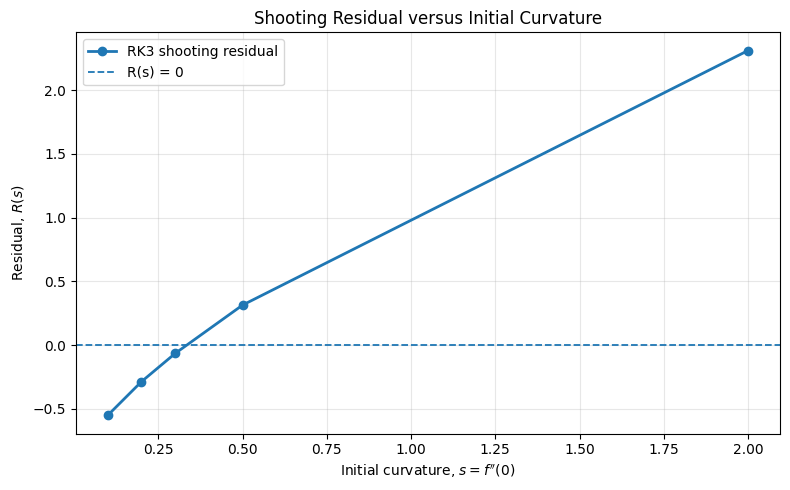

In [6]:
h_residual = 0.01
s_trial_values = np.array([0.1, 0.2, 0.3, 0.5, 2.0])
residual_values = np.array([
    shooting_residual(s, h_residual, method="RK3", eta_inf=eta_inf)
    for s in s_trial_values
])

residual_table = pd.DataFrame({
    "Initial curvature s": s_trial_values,
    "Residual R(s)": residual_values
})
display(residual_table)

plt.figure(figsize=(8, 5))
plt.plot(s_trial_values, residual_values, "o-", linewidth=2,
         label="RK3 shooting residual")
plt.axhline(0.0, linestyle="--", linewidth=1.3, label="R(s) = 0")
plt.xlabel(r"Initial curvature, $s=f''(0)$")
plt.ylabel(r"Residual, $R(s)$")
plt.title("Shooting Residual versus Initial Curvature")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Step-size convergence study

The step sizes are $h=[0.4,0.2,0.1,0.05,0.025]$. For a fair discretization-error study, the reference for each method is generated using that **same method**, the same finite computational boundary $\eta_\infty=10$, and a much finer step size $h_{\mathrm{ref}}=0.001$. This isolates the step-size error from the finite-domain truncation difference between $\eta_\infty=10$ and the infinite-domain Blasius problem.

For each method,

$$
E(h)=|s_h-s_{h,\mathrm{ref}}|,
\qquad
p=\frac{\ln(E(h)/E(h/2))}{\ln 2}.
$$

The accepted infinite-domain value is used separately for physical verification, not as the reference in this finite-domain discretization study.

In [7]:
# Method-specific fine-grid references on the same finite domain
h_reference = 0.001
s_ref_RK3, R_ref_RK3, _ = bisection_shooting(
    h_reference, "RK3", eta_inf, shooting_bracket, root_tol, max_iter
)
s_ref_RK4, R_ref_RK4, _ = bisection_shooting(
    h_reference, "RK4", eta_inf, shooting_bracket, root_tol, max_iter
)

s_RK3 = np.array([bisection_shooting(
    h, "RK3", eta_inf, shooting_bracket, root_tol, max_iter)[0]
    for h in h_values])
s_RK4 = np.array([bisection_shooting(
    h, "RK4", eta_inf, shooting_bracket, root_tol, max_iter)[0]
    for h in h_values])

error_RK3 = np.abs(s_RK3 - s_ref_RK3)
error_RK4 = np.abs(s_RK4 - s_ref_RK4)
order_RK3 = np.log(error_RK3[:-1] / error_RK3[1:]) / np.log(2.0)
order_RK4 = np.log(error_RK4[:-1] / error_RK4[1:]) / np.log(2.0)

convergence_table = pd.DataFrame({
    "h": h_values,
    "s_RK3": s_RK3,
    "RK3 error": error_RK3,
    "s_RK4": s_RK4,
    "RK4 error": error_RK4
})
order_table = pd.DataFrame({
    "Step transition": [f"{h_values[i]:g} to {h_values[i+1]:g}"
                        for i in range(len(h_values)-1)],
    "RK3 observed order": order_RK3,
    "RK4 observed order": order_RK4
})

print(f"RK3 finite-domain reference (h={h_reference}): {s_ref_RK3:.15f}")
print(f"RK4 finite-domain reference (h={h_reference}): {s_ref_RK4:.15f}")
display(convergence_table)
display(order_table)


RK3 finite-domain reference (h=0.001): 0.332057337203071
RK4 finite-domain reference (h=0.001): 0.332057337203702


,h,s_RK3,RK3 error,s_RK4,RK4 error
0,0.400,0.331977,8.019243e-05,0.332059,1.478635e-06
1,0.200,0.332050,7.738955e-06,0.332057,1.202469e-07
2,0.100,0.332057,8.038022e-07,0.332057,8.406840e-09
3,0.050,0.332057,8.961113e-08,0.332057,5.535469e-10
4,0.025,0.332057,1.050204e-08,0.332057,3.547601e-11


,Step transition,RK3 observed order,RK4 observed order
0,0.4 to 0.2,3.373256,3.620195
1,0.2 to 0.1,3.267226,3.838292
2,0.1 to 0.05,3.165091,3.924786
3,0.05 to 0.025,3.093009,3.963790


### 8.1 RK3 convergence plot

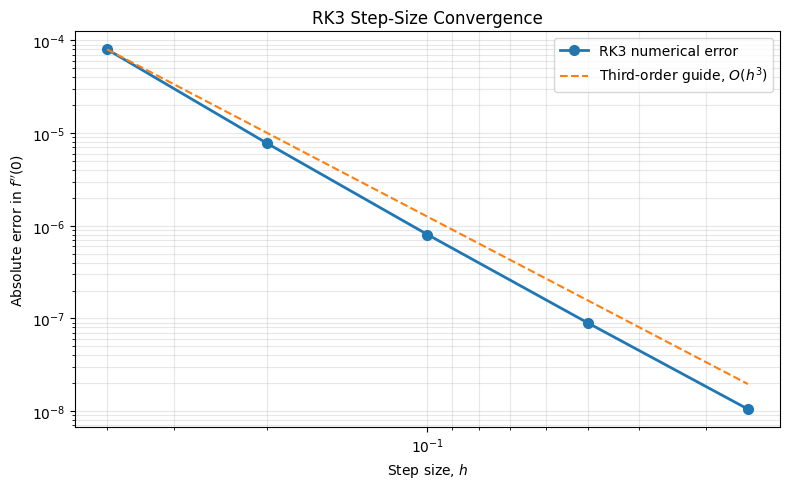

In [8]:
plt.figure(figsize=(8, 5))
plt.loglog(h_values, error_RK3, "o-", linewidth=2, markersize=7,
          label="RK3 numerical error")
ref_line_RK3 = error_RK3[0] * (h_values / h_values[0])**3
plt.loglog(h_values, ref_line_RK3, "--", linewidth=1.5,
          label=r"Third-order guide, $O(h^3)$")
plt.xlabel(r"Step size, $h$")
plt.ylabel(r"Absolute error in $f''(0)$")
plt.title("RK3 Step-Size Convergence")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


### 8.2 Combined RK3 and RK4 convergence plot

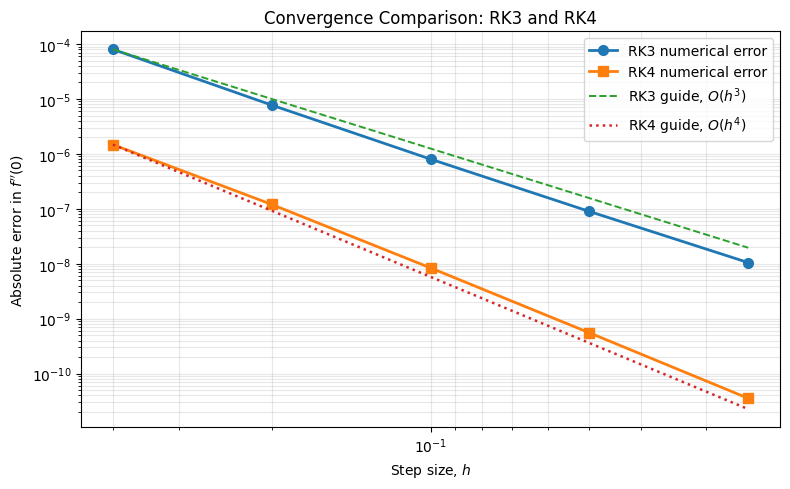

In [9]:
plt.figure(figsize=(8, 5))
plt.loglog(h_values, error_RK3, "o-", linewidth=2, markersize=7,
          label="RK3 numerical error")
plt.loglog(h_values, error_RK4, "s-", linewidth=2, markersize=7,
          label="RK4 numerical error")
ref_line_RK3 = error_RK3[0] * (h_values / h_values[0])**3
ref_line_RK4 = error_RK4[0] * (h_values / h_values[0])**4
plt.loglog(h_values, ref_line_RK3, "--", linewidth=1.4,
          label=r"RK3 guide, $O(h^3)$")
plt.loglog(h_values, ref_line_RK4, ":", linewidth=1.8,
          label=r"RK4 guide, $O(h^4)$")
plt.xlabel(r"Step size, $h$")
plt.ylabel(r"Absolute error in $f''(0)$")
plt.title("Convergence Comparison: RK3 and RK4")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


### 8.3 Interpretation of convergence

The RK3 observed orders should approach 3, while the RK4 observed orders should approach 4 as the computation enters the asymptotic range. The finite-domain, method-specific reference is important: comparing a finite-domain numerical solution directly with the infinite-domain reference introduces a small far-field truncation difference. That difference can dominate the error once the integration step becomes sufficiently small, distorting the observed order.

The fine-grid reference is itself a numerical approximation, so the reported errors are relative to that reference rather than exact mathematical errors. The value $h_{\mathrm{ref}}=0.001$ is much smaller than the study step sizes and provides a practical benchmark.

## 9. Blasius similarity profiles

The profiles are compared at the common step size $h=0.01$, using a separately determined shooting parameter for each integration method.

In [10]:
h_profile = 0.01
s_profile_RK3, residual_profile_RK3, _ = bisection_shooting(
    h_profile, "RK3", eta_inf, shooting_bracket, root_tol, max_iter
)
s_profile_RK4, residual_profile_RK4, _ = bisection_shooting(
    h_profile, "RK4", eta_inf, shooting_bracket, root_tol, max_iter
)

eta3, Y3, _ = RK3(s_profile_RK3, h_profile, eta_inf)
eta4, Y4, _ = RK4(s_profile_RK4, h_profile, eta_inf)

f3, fp3, fpp3 = Y3[:, 0], Y3[:, 1], Y3[:, 2]
f4, fp4, fpp4 = Y4[:, 0], Y4[:, 1], Y4[:, 2]

profile_summary = pd.DataFrame({
    "Quantity": ["f''(0)", "f'(10)", "f''(10)"],
    "RK3": [s_profile_RK3, fp3[-1], fpp3[-1]],
    "RK4": [s_profile_RK4, fp4[-1], fpp4[-1]]
})
display(profile_summary)


,Quantity,RK3,RK4
0,f''(0),3.320573e-01,3.320573e-01
1,f'(10),1.000000e+00,1.000000e+00
2,f''(10),8.442740e-09,8.442917e-09


### 9.1 Similarity function $f(\eta)$

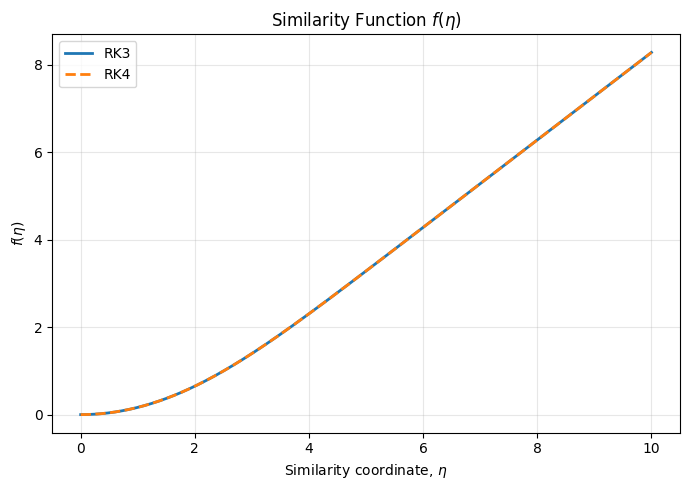

In [11]:
plt.figure(figsize=(7, 5))
plt.plot(eta3, f3, linewidth=2, label="RK3")
plt.plot(eta4, f4, "--", linewidth=2, label="RK4")
plt.xlabel(r"Similarity coordinate, $\eta$")
plt.ylabel(r"$f(\eta)$")
plt.title(r"Similarity Function $f(\eta)$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 9.2 Dimensionless velocity profile $f'(\eta)$

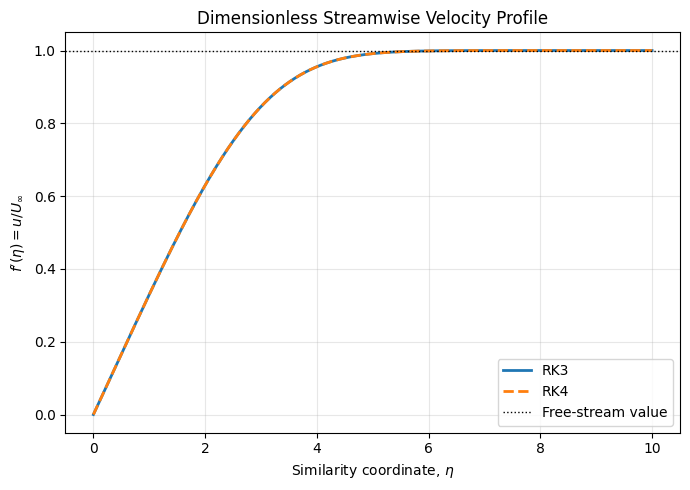

In [12]:
plt.figure(figsize=(7, 5))
plt.plot(eta3, fp3, linewidth=2, label="RK3")
plt.plot(eta4, fp4, "--", linewidth=2, label="RK4")
plt.axhline(1.0, color="black", linestyle=":", linewidth=1, label="Free-stream value")
plt.xlabel(r"Similarity coordinate, $\eta$")
plt.ylabel(r"$f'(\eta)=u/U_\infty$")
plt.title("Dimensionless Streamwise Velocity Profile")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 9.3 Velocity-gradient profile $f''(\eta)$

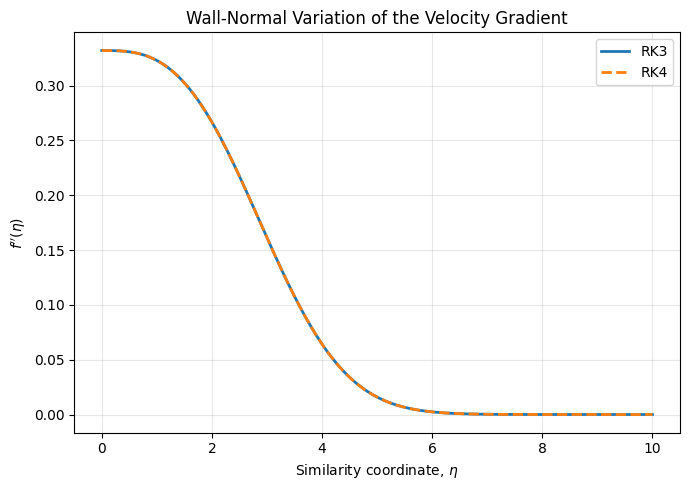

In [13]:
plt.figure(figsize=(7, 5))
plt.plot(eta3, fpp3, linewidth=2, label="RK3")
plt.plot(eta4, fpp4, "--", linewidth=2, label="RK4")
plt.xlabel(r"Similarity coordinate, $\eta$")
plt.ylabel(r"$f''(\eta)$")
plt.title("Wall-Normal Variation of the Velocity Gradient")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Results and physical interpretation

### 10.1 Shooting residual

The RK3 residual values for trial shooting parameters $s=0.1,0.2,0.3,0.5,2.0$ are evaluated in Section 7. The residual changes sign between $s=0.3$ and $s=0.5$, confirming that the selected interval brackets the required root.

### 10.2 Convergence behaviour

The convergence tables and log-log plots show how the estimated wall curvature changes with step size. RK3 is expected to exhibit third-order global convergence and RK4 fourth-order global convergence. The computed order values are displayed directly from the executed calculations; they should be interpreted alongside the log-log plots and the use of a fine-grid finite-domain reference.

### 10.3 Profile interpretation

- **Similarity function $f(\eta)$:** increases with the similarity coordinate and represents the integrated dimensionless velocity profile.
- **Dimensionless velocity $f'(\eta)$:** starts from zero at the wall due to the no-slip condition and approaches unity in the free stream.
- **Velocity gradient $f''(\eta)$:** is finite and positive at the wall and decays towards zero away from the wall, where the velocity becomes nearly uniform.

The RK3 and RK4 curves should nearly overlap at $h=0.01$, indicating close agreement between the two numerical solutions.

## 11. Verification against the accepted Blasius value

The accepted infinite-domain wall-curvature value is approximately

$$
f''(0)=0.3320573362.
$$

The finite-domain shooting parameters computed at $h=0.01$ are compared with this accepted value below. This is a physical verification check and is distinct from the method-specific finite-domain convergence reference used in Section 8.

In [14]:
verification_table = pd.DataFrame({
    "Method": ["RK3", "RK4"],
    "Computed f''(0)": [s_profile_RK3, s_profile_RK4],
    "Accepted infinite-domain value": [s_blasius_reference, s_blasius_reference],
    "Absolute difference": [abs(s_profile_RK3-s_blasius_reference),
                            abs(s_profile_RK4-s_blasius_reference)]
})
display(verification_table)

print("Terminal conditions at eta = 10")
print(f"RK3: f'(10) = {fp3[-1]:.15f}, f''(10) = {fpp3[-1]:.6e}")
print(f"RK4: f'(10) = {fp4[-1]:.15f}, f''(10) = {fpp4[-1]:.6e}")


,Method,Computed f''(0),Accepted infinite-domain value,Absolute difference
0,RK3,0.332057,0.332057,3.587735e-10
1,RK4,0.332057,0.332057,1.004628e-09


Terminal conditions at eta = 10
RK3: f'(10) = 1.000000000000008, f''(10) = 8.442740e-09
RK4: f'(10) = 1.000000000000006, f''(10) = 8.442917e-09


## 12. Conclusion

The Blasius boundary value problem was solved using the shooting method combined with third-order Kutta and classical fourth-order Runge–Kutta integration. The third-order equation was transformed into three first-order equations, and the unknown initial wall curvature was determined by bisection so that the finite-domain terminal velocity condition was satisfied.

The step-size study demonstrates the convergence of the shooting parameter as the integration step is reduced. A method-specific fine-grid reference at the same finite boundary was used to assess discretization error consistently. The RK3 and RK4 profile calculations produce the expected physical behaviour: the dimensionless velocity rises from zero at the wall to unity in the free stream, while the velocity gradient decays towards zero.

The computed wall curvature is close to the accepted Blasius value of approximately 0.3320573362. The exercise demonstrates the use of explicit Runge–Kutta methods, root-finding, and convergence analysis for a nonlinear boundary value problem.

## 13. Reproducibility notes

- Run the notebook from top to bottom so that all functions and results are defined in order.
- The computational boundary is $\eta_\infty=10$.
- The convergence study uses $h=[0.4,0.2,0.1,0.05,0.025]$.
- The method-specific finite-domain reference uses $h_{\mathrm{ref}}=0.001$.
- The profile comparison uses $h=0.01$.
- Required packages: NumPy, Matplotlib, and Pandas.
